# Logistic Regression

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import accuracy_score, roc_auc_score , roc_curve, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [13]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore',category = ConvergenceWarning)

In [2]:
df = pd.read_csv('diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
feature_Cols = df.columns.to_list()[0:-1]
x = df[feature_Cols]
y = df['Outcome']

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

In [9]:
# Scaling Pipeline
scale_pipeline = Pipeline(steps = [
        ('scale',StandardScaler())
        ])

In [10]:
# preprocessing Pipeline
preprocessor = ColumnTransformer(transformers=[
    ('scaled_pipeline',scale_pipeline,feature_Cols)
])

preprocessor

ColumnTransformer(transformers=[('scaled_pipeline',
                                 Pipeline(steps=[('scale', StandardScaler())]),
                                 ['Pregnancies', 'Glucose', 'BloodPressure',
                                  'SkinThickness', 'Insulin', 'BMI',
                                  'DiabetesPedigreeFunction', 'Age'])])

In [28]:
# model train
model = Pipeline(
    steps=[
        ('preporcess',preprocessor),
        ('classify',LogisticRegression())
    ]
)

# hyperparameter tuning
param_grid = {
    'classify__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'classify__penalty': ['l1', 'l2'],
    'classify__solver': ['liblinear', 'saga'],
    'classify__max_iter': [100, 200, 500, 1000],
    'classify__class_weight': [None, 'balanced']
}

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv = 5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(x_train, y_train)

print('best model: ',grid.best_estimator_)
print('best score: ',grid.best_score_)
print('best hyperparameters: ',grid.best_params_)

best model:  Pipeline(steps=[('preporcess',
                 ColumnTransformer(transformers=[('scaled_pipeline',
                                                  Pipeline(steps=[('scale',
                                                                   StandardScaler())]),
                                                  ['Pregnancies', 'Glucose',
                                                   'BloodPressure',
                                                   'SkinThickness', 'Insulin',
                                                   'BMI',
                                                   'DiabetesPedigreeFunction',
                                                   'Age'])])),
                ('classify',
                 LogisticRegression(C=0.1, penalty='l1', solver='saga'))])
best score:  0.7655204584832733
best hyperparameters:  {'classify__C': 0.1, 'classify__class_weight': None, 'classify__max_iter': 100, 'classify__penalty': 'l1', 'classify__solver': 'saga'}


### All the features

accuracy_score:  0.7662337662337663
confusion matrix...



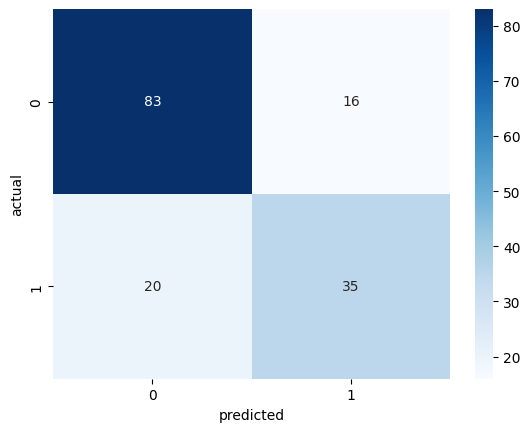

In [29]:
logistic_best = grid.best_estimator_
y_Pred =logistic_best.predict(x_test)

print('accuracy_score: ',accuracy_score(y_test, y_Pred))
print('confusion matrix...\n')
sns.heatmap(confusion_matrix(y_test, y_Pred), annot=True, cmap = 'Blues')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.show()

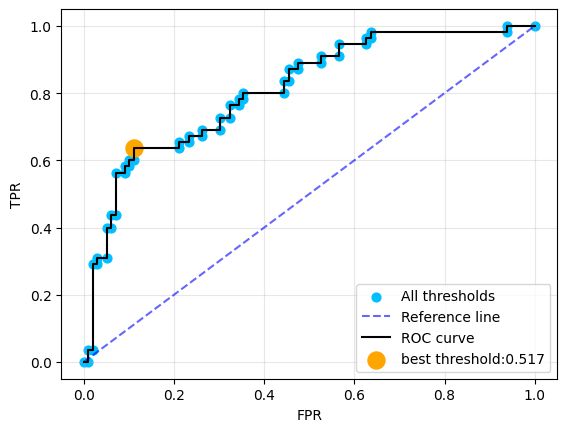

In [30]:
# ROC Curve
y_score = logistic_best.predict_proba(x_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_score)

# optimal threshold
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]


plt.scatter(fpr, tpr, color = 'deepskyblue', s = 40, label = 'All thresholds')
plt.plot([0,1],[0,1], color = 'blue', alpha = 0.6, ls = 'dashed', label = 'Reference line')
plt.plot(fpr, tpr, color = 'k', label = 'ROC curve')
plt.scatter(fpr[optimal_idx], tpr[optimal_idx], color = 'orange', s = 150, label = f'best threshold:{optimal_threshold:.3f}')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()
plt.grid(True, alpha = 0.3)
plt.show()

In [31]:
print("AUC score:",roc_auc_score(y_test, y_score))

AUC score: 0.8108356290174472


### All the IMPORTANT features

In [32]:
feature_imp = pd.DataFrame({
    'feature' : x_train.columns,
    'coef' : logistic_best.named_steps['classify'].coef_[0],
    'Importance': abs(logistic_best.named_steps['classify'].coef_[0])
})

feature_imp = feature_imp.sort_values(ascending=False, by = 'Importance')
feature_imp

,feature,coef,Importance
1,Glucose,0.886730,0.886730
5,BMI,0.589244,0.589244
7,Age,0.331782,0.331782
0,Pregnancies,0.139848,0.139848
6,DiabetesPedigreeFunction,0.117770,0.117770
2,BloodPressure,-0.065561,0.065561
4,Insulin,-0.033035,0.033035
3,SkinThickness,0.000000,0.000000


In [50]:
selected_features = feature_imp[feature_imp['Importance'] > 0.04]
selected_cols = selected_features['feature'].tolist()
selected_cols

['Glucose',
 'BMI',
 'Age',
 'Pregnancies',
 'DiabetesPedigreeFunction',
 'BloodPressure']

In [51]:
x_reduced = df[selected_cols]
x_train_reduced, x_test_reduced, y_trainr, y_testr = train_test_split(x_reduced, y, test_size=0.2, random_state=42) 

In [52]:
# model train
best_params = {
    key.replace('classify__', ''): value
    for key, value in grid.best_params_.items()
}

# Final model with scaling
final_model = Pipeline(steps=[
    ('scale', StandardScaler()),
    ('classify', LogisticRegression(**best_params))
])
final_model.fit(x_train_reduced, y_trainr)

Pipeline(steps=[('scale', StandardScaler()),
                ('classify',
                 LogisticRegression(C=0.1, penalty='l1', solver='saga'))])

In [53]:
# Predict
y_pred_reduced = final_model.predict(x_test_reduced)

In [54]:
print("Reduced Model Accuracy:",
      accuracy_score(y_testr, y_pred_reduced))

y_prob_reduced = final_model.predict_proba(x_test_reduced)[:, 1]

print("Reduced Model AUC:",
      roc_auc_score(y_testr, y_prob_reduced))

Reduced Model Accuracy: 0.7662337662337663
Reduced Model AUC: 0.8119375573921028


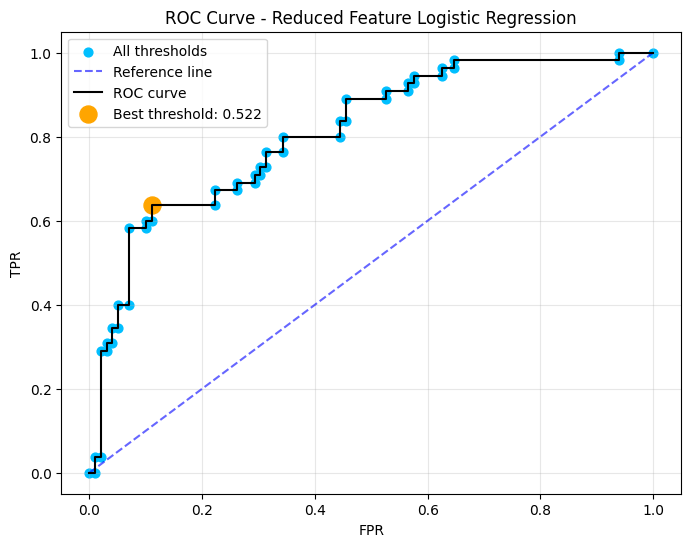

Optimal Threshold: 0.5216494420151911
Reduced Model AUC: 0.8119375573921028


In [56]:
# ROC Curve - Reduced Feature Model
y_score_reduced = final_model.predict_proba(x_test_reduced)[:, 1]
fpr, tpr, thresholds = roc_curve(y_testr, y_score_reduced)

# Optimal threshold
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

plt.figure(figsize=(8, 6))
plt.scatter(fpr, tpr,color='deepskyblue',s=40,label='All thresholds')
plt.plot([0, 1], [0, 1],color='blue',alpha=0.6,ls='dashed',label='Reference line')
plt.plot(fpr, tpr,color='black',label='ROC curve')
plt.scatter(fpr[optimal_idx],tpr[optimal_idx],color='orange',s=150,label=f'Best threshold: {optimal_threshold:.3f}')

plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC Curve - Reduced Feature Logistic Regression')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Optimal Threshold:", optimal_threshold)
print("Reduced Model AUC:", roc_auc_score(y_testr, y_score_reduced))

In [55]:
comparison = pd.DataFrame({
    'Model': ['All Features', 'Reduced Features'],
    'Accuracy': [
        accuracy_score(y_test, y_Pred),
        accuracy_score(y_testr, y_pred_reduced)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_score),
        roc_auc_score(y_testr, y_prob_reduced)
    ]
})

comparison

,Model,Accuracy,ROC-AUC
0,All Features,0.766234,0.810836
1,Reduced Features,0.766234,0.811938
